# First-pass High-Risk Classifier

This notebook trains an XGBoost classifier to predict whether an eligible account will be labelled `high_risk` in its **next monthly snapshot**. It uses a chronological holdout (June-August 2018 target months) rather than a random row split. The current snapshot's label columns are excluded from predictors.

This is a first baseline, not a production model. The label is rule-defined, so interpret results as forecasting persistence/transition in that operational definition. Same accounts may occur in train and test because this evaluates future months for accounts already in the portfolio.

In [1]:
from pathlib import Path
import ctypes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Conda's OpenMP runtime only when no standard Homebrew runtime is present.
standard_libomp = [
    Path('/opt/homebrew/opt/libomp/lib/libomp.dylib'),
    Path('/usr/local/opt/libomp/lib/libomp.dylib'),
]
conda_libomp = Path('/opt/anaconda3/lib/libomp.dylib')
if not any(path.exists() for path in standard_libomp) and conda_libomp.exists():
    ctypes.CDLL(str(conda_libomp), mode=ctypes.RTLD_GLOBAL)

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, RocCurveDisplay,
    PrecisionRecallDisplay,
)

pd.set_option('display.max_columns', 100)
RANDOM_STATE = 42
TEST_START = pd.Timestamp('2018-06-01')
DECISION_THRESHOLD = 0.50

project_root = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / 'data' / 'raw').is_dir() and (candidate / 'outputs').is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Could not find project root containing data/raw and outputs.')
DATA_PATH = project_root / 'outputs' / 'rolling_account_risk_dataset.csv'
OUTPUT_DIR = project_root / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)

## Load and define the forecasting rows
At feature month t, the account must have at least three orders in the prior 18 months. The target is the following month's high-risk/churn/loss label, and training rows are retained only when that next-month snapshot is also eligible, so an undefined label is never coded as a negative. Every feature is taken from the builder's point-in-time snapshot using orders/reviews dated no later than that snapshot. Missing numeric features remain NaN; XGBoost routes these natively, while accounts below the eligibility threshold receive no probabilities.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'{DATA_PATH} not found. Run build_rolling_risk_dataset.py first.'
    )

risk_df = pd.read_csv(
    DATA_PATH,
    parse_dates=['snapshot_month', 'latest_order_date'],
)
risk_df = risk_df.sort_values(['account_id', 'snapshot_month']).reset_index(drop=True)
account_groups = risk_df.groupby('account_id', sort=False)
for label in ['high_risk', 'churn', 'loss', 'eligible']:
    risk_df[f'target_{label}'] = account_groups[label].shift(-1)
risk_df['target_month'] = account_groups['snapshot_month'].shift(-1)

month_gap = (
    risk_df['target_month'].dt.to_period('M').astype('int64')
    - risk_df['snapshot_month'].dt.to_period('M').astype('int64')
)
valid_target = risk_df['target_eligible'].eq(1)
model_df = risk_df.loc[
    risk_df['eligible'].eq(1)
    & valid_target
    & risk_df['target_high_risk'].notna()
    & month_gap.eq(1)
].copy()
for label in ['high_risk', 'churn', 'loss']:
    model_df[f'target_{label}'] = model_df[f'target_{label}'].astype(int)

print(f'Rolling snapshots loaded: {len(risk_df):,}')
print(f'Eligible one-month forecasting rows with defined next-month targets: {len(model_df):,}')
print(f'Eligible accounts represented: {model_df.account_id.nunique():,}')
print(f'Feature snapshot span: {model_df.snapshot_month.min().date()} to {model_df.snapshot_month.max().date()}')
print(f'Target snapshot span: {model_df.target_month.min().date()} to {model_df.target_month.max().date()}')
print(f'Next-month high-risk rate: {model_df.target_high_risk.mean():.3f}')

Rolling snapshots loaded: 199,297
Eligible one-month forecasting rows with defined next-month targets: 83,503
Eligible accounts represented: 9,372
Feature snapshot span: 2017-02-28 to 2018-07-31
Target snapshot span: 2017-03-31 to 2018-08-31
Next-month high-risk rate: 0.363


## Chronological split and feature audit
The test set contains target months from June 2018 onward. The prediction snapshot and target snapshot must both meet the three-order/18-month eligibility rule. IDs, dates, labels, and geographic coordinates/context are excluded. The retained numeric feature list is deliberately compact and uses only point-in-time information; no missing-value imputation is applied because XGBoost handles NaN values natively.

In [3]:
excluded_columns = {
    'account_id', 'snapshot_month', 'target_month', 'latest_order_date',
    'eligible', 'churn', 'loss', 'high_risk', 'target_high_risk',
    'target_churn', 'target_loss', 'target_eligible', 'city', 'state',
    'lat', 'lng', 'city_account_count', 'state_account_count',
    'city_avg_revenue_18m', 'state_avg_revenue_18m',
}

# Keep high-signal behavior/value features and compact, baseline-relative review signals.
feature_cols = [
    'orders_last_18m', 'revenue_last_18m', 'avg_order_value_18m', 'max_order_value_18m',
    'days_since_last_order', 'normal_cycle_days',
    'recent_3m_orders', 'recent_6m_orders',
    'revenue_drop_ratio_3m', 'revenue_drop_ratio_6m', 'recent_3m_revenue',
    'active_months_3m', 'active_months_6m', 'active_months_12m', 'active_months_18m',
    'latest_order_value', 'avg_historic_order_value', 'value_drop_ratio',
    'recent_review_count_6m', 'latest_review_vs_prior_avg',
    'review_score_trend_3m', 'negative_review_share_6m',
]
missing_features = sorted(set(feature_cols) - set(model_df.columns))
if missing_features:
    raise KeyError(f'Rerun build_rolling_risk_dataset.py to generate features: {missing_features}')

train_mask = model_df['target_month'] < TEST_START
test_mask = model_df['target_month'] >= TEST_START
train_df = model_df.loc[train_mask].copy()
test_df = model_df.loc[test_mask].copy()

if train_df.empty or test_df.empty:
    raise ValueError('The chronological split produced an empty train or test set; check TEST_START and available months.')
for target in ['target_high_risk', 'target_churn', 'target_loss']:
    if train_df[target].nunique() < 2:
        raise ValueError(f'Training target {target} contains only one class.')
    if test_df[target].nunique() < 2:
        raise ValueError(f'Test target {target} contains only one class; ROC-AUC cannot be computed.')

X_train = train_df[feature_cols].replace([np.inf, -np.inf], np.nan)
X_test = test_df[feature_cols].replace([np.inf, -np.inf], np.nan)
y_train = train_df['target_high_risk']
y_test = test_df['target_high_risk']
y_churn_train = train_df['target_churn']
y_churn_test = test_df['target_churn']
y_loss_train = train_df['target_loss']
y_loss_test = test_df['target_loss']

split_summary = pd.DataFrame({
    'rows': [len(train_df), len(test_df)],
    'accounts': [train_df.account_id.nunique(), test_df.account_id.nunique()],
    'target_month_start': [train_df.target_month.min(), test_df.target_month.min()],
    'target_month_end': [train_df.target_month.max(), test_df.target_month.max()],
    'high_risk_rate': [y_train.mean(), y_test.mean()],
    'churn_rate': [y_churn_train.mean(), y_churn_test.mean()],
    'loss_rate': [y_loss_train.mean(), y_loss_test.mean()],
}, index=['train', 'test'])
display(split_summary)
print(f'Predictor count: {len(feature_cols)}')
display(pd.DataFrame({
    'missing_count': X_train.isna().sum(),
    'missing_share': X_train.isna().mean(),
}).sort_values('missing_share', ascending=False).head(15))

,rows,accounts,target_month_start,target_month_end,high_risk_rate,churn_rate,loss_rate
train,56687,8141,2017-03-31,2018-05-31,0.348387,0.185051,0.198458
test,26816,9372,2018-06-30,2018-08-31,0.392639,0.245898,0.193690


Predictor count: 22


,missing_count,missing_share
review_score_trend_3m,20813,0.367156
revenue_drop_ratio_6m,16730,0.295129
revenue_drop_ratio_3m,12699,0.224020
negative_review_share_6m,1346,0.023744
latest_review_vs_prior_avg,478,0.008432
normal_cycle_days,38,0.000670
value_drop_ratio,2,0.000035
active_months_12m,0,0.000000
recent_review_count_6m,0,0.000000
avg_historic_order_value,0,0.000000


## Fit the first XGBoost model
XGBoost handles missing numeric values natively. `scale_pos_weight` addresses class imbalance during fitting; the untouched chronological test set is used only for final evaluation.

In [4]:
def fit_binary_classifier(features, target):
    positive_count = int(target.sum())
    negative_count = int(len(target) - positive_count)
    classifier = XGBClassifier(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.04,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2.0,
        min_child_weight=3,
        scale_pos_weight=negative_count / positive_count,
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    classifier.fit(features, target)
    return classifier

model = fit_binary_classifier(X_train, y_train)
churn_model = fit_binary_classifier(X_train, y_churn_train)
loss_model = fit_binary_classifier(X_train, y_loss_train)

test_probability = model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= DECISION_THRESHOLD).astype(int)
test_churn_probability = churn_model.predict_proba(X_test)[:, 1]
test_loss_probability = loss_model.predict_proba(X_test)[:, 1]

print(f'Trained three XGBoost evaluation classifiers on {len(X_train):,} eligible rows and {len(feature_cols)} features.')
print('The churn and loss probabilities are separate component risks; they are not additive.')

Trained three XGBoost evaluation classifiers on 56,687 eligible rows and 22 features.
The churn and loss probabilities are separate component risks; they are not additive.


## Score the current account roster
After the holdout classifiers are fitted, separate scoring classifiers are refit on all eligible, labeled historical rows. The roster includes every account; fewer than three orders in the trailing 18 months results in `insufficient_data` and blank probabilities. The scoring classifiers' current probabilities are conditional on the same next-snapshot eligibility definition used for training.

In [5]:
latest_status_path = OUTPUT_DIR / 'latest_account_scoring_status.csv'
if not latest_status_path.exists():
    raise FileNotFoundError('Run build_rolling_risk_dataset.py to create the latest account status roster.')

# Refit deployment models on all labeled history; the temporal test models above remain untouched.
X_all = model_df[feature_cols].replace([np.inf, -np.inf], np.nan)
current_model = fit_binary_classifier(X_all, model_df['target_high_risk'])
current_churn_model = fit_binary_classifier(X_all, model_df['target_churn'])
current_loss_model = fit_binary_classifier(X_all, model_df['target_loss'])

scoring_status = pd.read_csv(latest_status_path, parse_dates=['snapshot_month'])
latest_snapshot = scoring_status['snapshot_month'].max()
latest_features = risk_df.loc[
    risk_df['snapshot_month'].eq(latest_snapshot),
    ['account_id', *feature_cols],
].copy()
current_scoring = scoring_status.merge(latest_features, on='account_id', how='left', validate='one_to_one')

# Importance is relative 18-month revenue position within the full current account roster.
current_scoring['account_revenue_18m'] = current_scoring['revenue_last_18m'].fillna(0.0)
current_scoring['account_importance_score'] = current_scoring['account_revenue_18m'].rank(
    method='average', pct=True
)

eligible_mask = current_scoring['eligible'].eq(1)
if current_scoring.loc[eligible_mask, feature_cols].isna().all(axis=1).any():
    raise ValueError('An eligible account has no feature snapshot; rebuild the rolling dataset.')

for column in ['high_risk_probability', 'churn_probability', 'loss_probability']:
    current_scoring[column] = np.nan
for rank in range(1, 4):
    for prefix in ['risk_driver', 'protective_factor']:
        for suffix in ['', '_value', '_log_odds']:
            current_scoring[f'{prefix}_{rank}{suffix}'] = None

local_contributions = []
if eligible_mask.any():
    X_current = current_scoring.loc[eligible_mask, feature_cols].replace([np.inf, -np.inf], np.nan)
    current_scoring.loc[eligible_mask, 'high_risk_probability'] = current_model.predict_proba(X_current)[:, 1]
    current_scoring.loc[eligible_mask, 'churn_probability'] = current_churn_model.predict_proba(X_current)[:, 1]
    current_scoring.loc[eligible_mask, 'loss_probability'] = current_loss_model.predict_proba(X_current)[:, 1]

    import xgboost as xgb
    current_matrix = xgb.DMatrix(X_current, feature_names=feature_cols)
    contribution_matrix = current_model.get_booster().predict(current_matrix, pred_contribs=True)
    current_contributions = contribution_matrix[:, :-1]
    current_bias = contribution_matrix[:, -1]
    current_margin = current_model.predict(X_current, output_margin=True)
    assert np.allclose(current_contributions.sum(axis=1) + current_bias, current_margin, atol=1e-4)
    current_values = X_current.to_numpy()
    eligible_rows = current_scoring.loc[eligible_mask]

    for local_index, (row_index, row) in enumerate(eligible_rows.iterrows()):
        contributions = current_contributions[local_index]
        positive = [i for i in np.argsort(-contributions) if contributions[i] > 0][:3]
        negative = [i for i in np.argsort(contributions) if contributions[i] < 0][:3]
        for rank, feature_index in enumerate(positive, start=1):
            current_scoring.at[row_index, f'risk_driver_{rank}'] = feature_cols[feature_index]
            current_scoring.at[row_index, f'risk_driver_{rank}_value'] = current_values[local_index, feature_index]
            current_scoring.at[row_index, f'risk_driver_{rank}_log_odds'] = float(contributions[feature_index])
        for rank, feature_index in enumerate(negative, start=1):
            current_scoring.at[row_index, f'protective_factor_{rank}'] = feature_cols[feature_index]
            current_scoring.at[row_index, f'protective_factor_{rank}_value'] = current_values[local_index, feature_index]
            current_scoring.at[row_index, f'protective_factor_{rank}_log_odds'] = float(contributions[feature_index])

        account_id = row['account_id']
        snapshot_month = row['snapshot_month']
        account_frame = pd.DataFrame({
            'account_id': account_id,
            'snapshot_month': snapshot_month,
            'feature': feature_cols,
            'feature_value': current_values[local_index],
            'contribution_log_odds': contributions,
        })
        account_frame['contribution_direction'] = np.where(
            account_frame['contribution_log_odds'] > 0, 'increases_risk',
            np.where(account_frame['contribution_log_odds'] < 0, 'reduces_risk', 'no_effect'),
        )
        local_contributions.append(account_frame)

current_feature_contributions = (
    pd.concat(local_contributions, ignore_index=True)
    if local_contributions
    else pd.DataFrame(columns=['account_id', 'snapshot_month', 'feature', 'feature_value', 'contribution_log_odds', 'contribution_direction'])
)
current_scoring['predicted_high_risk'] = np.where(
    eligible_mask,
    current_scoring['high_risk_probability'].ge(DECISION_THRESHOLD).astype(int),
    np.nan,
)
current_scoring['priority_score'] = np.nan
current_scoring.loc[eligible_mask, 'priority_score'] = (
    current_scoring.loc[eligible_mask, 'high_risk_probability']
    * (0.5 + 0.5 * current_scoring.loc[eligible_mask, 'account_importance_score'])
)
current_scoring['priority_rank'] = np.nan
current_scoring.loc[eligible_mask, 'priority_rank'] = current_scoring.loc[eligible_mask, 'priority_score'].rank(
    method='first', ascending=False
).astype(int)
current_scoring = current_scoring.sort_values(
    ['eligible', 'priority_score'], ascending=[False, False], na_position='last'
).reset_index(drop=True)
print(f'Latest scoring snapshot: {latest_snapshot.date()}')
print(f'Scored: {int(eligible_mask.sum()):,}; insufficient data: {int((~eligible_mask).sum()):,}')
print(f'Deployment models refit on {len(X_all):,} eligible, labeled historical rows.')
print('Priority = high-risk probability * (0.5 + 0.5 * revenue importance percentile).')
print(f'Per-feature local contributions calculated: {len(current_feature_contributions):,} rows.')
display(current_scoring.head(10))

Latest scoring snapshot: 2018-08-31
Scored: 9,577; insufficient data: 5,412
Deployment models refit on 83,503 eligible, labeled historical rows.
Priority = high-risk probability * (0.5 + 0.5 * revenue importance percentile).
Per-feature local contributions calculated: 210,694 rows.


,account_id,snapshot_month,eligibility_order_count_18m,eligible,score_status,orders_last_18m,revenue_last_18m,avg_order_value_18m,max_order_value_18m,days_since_last_order,normal_cycle_days,recent_3m_orders,recent_6m_orders,revenue_drop_ratio_3m,revenue_drop_ratio_6m,recent_3m_revenue,active_months_3m,active_months_6m,active_months_12m,active_months_18m,latest_order_value,avg_historic_order_value,value_drop_ratio,recent_review_count_6m,latest_review_vs_prior_avg,review_score_trend_3m,negative_review_share_6m,account_revenue_18m,account_importance_score,high_risk_probability,churn_probability,loss_probability,risk_driver_1,risk_driver_1_value,risk_driver_1_log_odds,protective_factor_1,protective_factor_1_value,protective_factor_1_log_odds,risk_driver_2,risk_driver_2_value,risk_driver_2_log_odds,protective_factor_2,protective_factor_2_value,protective_factor_2_log_odds,risk_driver_3,risk_driver_3_value,risk_driver_3_log_odds,protective_factor_3,protective_factor_3_value,protective_factor_3_log_odds,predicted_high_risk,priority_score,priority_rank
0,A37550,2018-08-31,32,1,eligible_for_scoring,32.0,4935.41,154.231562,1146.00,355.0,5.0,0.0,0.0,NaN,0.000000,0.00,0.0,0.0,1.0,7.0,53.87,157.469032,0.342099,0.0,-3.064516,NaN,NaN,4935.41,0.985723,0.987767,0.988875,0.042881,days_since_last_order,355.0,1.570967,value_drop_ratio,0.342099,-0.072521,normal_cycle_days,5.0,1.204828,latest_order_value,53.87,-0.012262,revenue_drop_ratio_3m,NaN,0.198734,None,None,None,1.0,0.980715,1.0
1,A23953,2018-08-31,4,1,eligible_for_scoring,4.0,3454.78,863.695000,2999.99,263.0,62.0,0.0,0.0,NaN,0.000000,0.00,0.0,0.0,2.0,4.0,219.90,1078.293333,0.203933,0.0,-3.333333,NaN,NaN,3454.78,0.968510,0.990916,0.965323,0.989410,days_since_last_order,263.0,1.438059,normal_cycle_days,62.0,-0.106357,value_drop_ratio,0.203933,0.979245,latest_order_value,219.9,-0.003432,avg_order_value_18m,863.695,0.729529,None,None,None,1.0,0.975314,2.0
2,A17506,2018-08-31,6,1,eligible_for_scoring,6.0,7400.98,1233.496667,6499.00,111.0,37.0,0.0,3.0,0.00000,1.052007,0.00,0.0,2.0,3.0,5.0,130.00,1454.196000,0.089396,4.0,0.400000,NaN,0.000000,7400.98,0.996264,0.974448,0.883200,0.981910,value_drop_ratio,0.089396,0.978643,revenue_drop_ratio_3m,0.0,-0.059255,avg_order_value_18m,1233.496667,0.822979,active_months_18m,5.0,-0.032955,days_since_last_order,111.0,0.554854,orders_last_18m,6.0,-0.009303,1.0,0.972627,3.0
3,A22775,2018-08-31,27,1,eligible_for_scoring,27.0,3704.76,137.213333,1300.00,347.0,4.0,0.0,0.0,NaN,0.000000,0.00,0.0,0.0,1.0,7.0,99.99,138.645000,0.721194,0.0,0.035714,NaN,NaN,3704.76,0.972913,0.983160,0.982012,0.032647,days_since_last_order,347.0,1.414514,value_drop_ratio,0.721194,-0.122715,normal_cycle_days,4.0,1.303306,latest_order_value,99.99,-0.046046,revenue_last_18m,3704.76,0.231692,latest_review_vs_prior_avg,0.035714,-0.023948,1.0,0.969845,4.0
4,A35340,2018-08-31,3,1,eligible_for_scoring,3.0,4451.89,1483.963333,4099.99,120.0,55.0,0.0,2.0,0.00000,21.270585,0.00,0.0,2.0,3.0,3.0,152.00,2149.945000,0.070699,2.0,0.000000,NaN,0.000000,4451.89,0.981853,0.978362,0.803701,0.983464,value_drop_ratio,0.070699,1.396537,normal_cycle_days,55.0,-0.188102,avg_order_value_18m,1483.963333,0.806891,revenue_drop_ratio_3m,0.0,-0.032135,days_since_last_order,120.0,0.551691,latest_order_value,152.0,-0.011661,1.0,0.969485,5.0
5,A04559,2018-08-31,5,1,eligible_for_scoring,5.0,4434.77,886.954000,3999.90,88.0,128.0,1.0,3.0,0.34621,4.116720,89.98,1.0,2.0,3.0,4.0,89.98,1086.197500,0.082839,3.0,1.000000,2.0,0.333333,4434.77,0.981520,0.974485,0.004703,0.987482,value_drop_ratio,0.082839,2.061393,normal_cycle_days,128.0,-0.70215,avg_order_value_18m,886.954,0.805603,latest_order_value,89.98,-0.034807,avg_historic_order_value,1086.1975,0.651078,review_score_trend_3m,2.0,-0.013744,1.0,0.965480,6.0
6,A89114,2018-08-31,5,1,eligible_for_scoring,5.0,3836.28,767.256000,3597.00,48.0,98.5,1.0,1.0,NaN,0.151603,31.50,1.0,1.0,2.0,3.0,31.50,951.195000,0.033116,1.0,1.250000,NaN,0.000000,3836.28,0.974848,0.977762,0.002694,0.988028,va

## Evaluation
ROC-AUC and average precision evaluate ranking across thresholds. The 0.50-threshold metrics and threshold table expose classification trade-offs; top-k precision/recall reflects a rep team acting on only the highest-ranked accounts. Always compare against the test prevalence baseline shown below.

In [6]:
test_prevalence = float(y_test.mean())
metrics = pd.Series({
    'test_rows': len(y_test),
    'test_accounts': test_df.account_id.nunique(),
    'test_high_risk_rate_baseline': test_prevalence,
    'high_risk_roc_auc': roc_auc_score(y_test, test_probability),
    'high_risk_average_precision_pr_auc': average_precision_score(y_test, test_probability),
    'high_risk_brier_score': brier_score_loss(y_test, test_probability),
    'churn_roc_auc': roc_auc_score(y_churn_test, test_churn_probability),
    'churn_average_precision_pr_auc': average_precision_score(y_churn_test, test_churn_probability),
    'loss_roc_auc': roc_auc_score(y_loss_test, test_loss_probability),
    'loss_average_precision_pr_auc': average_precision_score(y_loss_test, test_loss_probability),
    'accuracy_at_threshold': accuracy_score(y_test, test_prediction),
    'balanced_accuracy_at_threshold': balanced_accuracy_score(y_test, test_prediction),
    'precision_at_threshold': precision_score(y_test, test_prediction, zero_division=0),
    'recall_at_threshold': recall_score(y_test, test_prediction, zero_division=0),
    'f1_at_threshold': f1_score(y_test, test_prediction, zero_division=0),
})
display(metrics.to_frame('value').style.format('{:.4f}'))
print(classification_report(y_test, test_prediction, target_names=['not high risk', 'high risk'], zero_division=0))

threshold_rows = []
for threshold in [0.20, 0.35, 0.50, 0.65, 0.80]:
    prediction = (test_probability >= threshold).astype(int)
    threshold_rows.append({
        'threshold': threshold,
        'flagged_accounts': int(prediction.sum()),
        'precision': precision_score(y_test, prediction, zero_division=0),
        'recall': recall_score(y_test, prediction, zero_division=0),
        'f1': f1_score(y_test, prediction, zero_division=0),
    })
display(pd.DataFrame(threshold_rows).set_index('threshold').style.format('{:.3f}'))

,value
test_rows,26816.0000
test_accounts,9372.0000
test_high_risk_rate_baseline,0.3926
high_risk_roc_auc,0.8986
high_risk_average_precision_pr_auc,0.8277
high_risk_brier_score,0.1253
churn_roc_auc,0.9512
churn_average_precision_pr_auc,0.8176
loss_roc_auc,0.9030
loss_average_precision_pr_auc,0.7523


               precision    recall  f1-score   support

not high risk       0.90      0.82      0.86     16287
    high risk       0.75      0.86      0.81     10529

     accuracy                           0.84     26816
    macro avg       0.83      0.84      0.83     26816
 weighted avg       0.84      0.84      0.84     26816



,flagged_accounts,precision,recall,f1
threshold,,,,
0.200000,17155.000,0.589,0.959,0.730
0.350000,14015.000,0.693,0.923,0.792
0.500000,12043.000,0.755,0.863,0.805
0.650000,10152.000,0.793,0.765,0.779
0.800000,6912.000,0.838,0.550,0.664


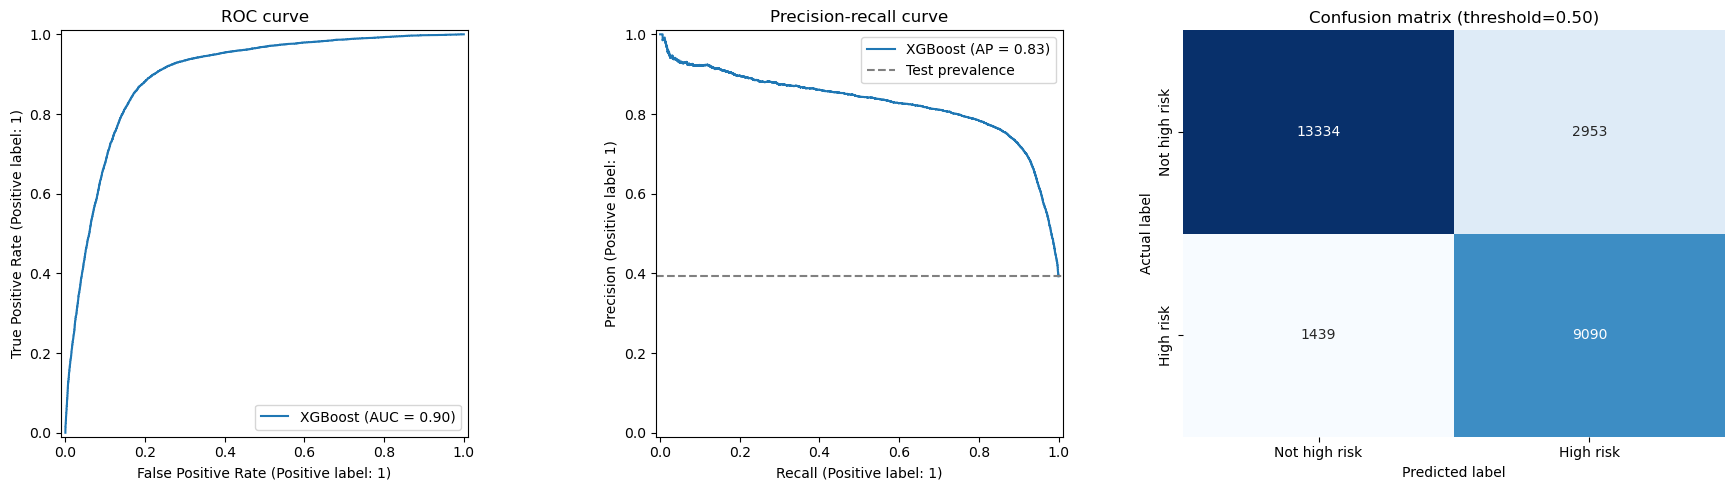

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[0], name='XGBoost')
axes[0].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[1], name='XGBoost')
axes[1].axhline(test_prevalence, color='gray', linestyle='--', label='Test prevalence')
axes[1].legend()
axes[1].set_title('Precision-recall curve')
cm = confusion_matrix(y_test, test_prediction, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[2])
axes[2].set(
    title=f'Confusion matrix (threshold={DECISION_THRESHOLD:.2f})',
    xlabel='Predicted label', ylabel='Actual label',
    xticklabels=['Not high risk', 'High risk'],
    yticklabels=['Not high risk', 'High risk'],
)
plt.tight_layout()
plt.show()

,accounts_contacted,precision_at_k,recall_at_k,lift_vs_prevalence
top_share,,,,
0.050000,1341.000,0.923,0.118,2.351
0.100000,2682.000,0.890,0.227,2.268
0.200000,5364.000,0.855,0.435,2.177


,feature,average_gain,split_count
0,value_drop_ratio,177.480026,521.0
1,active_months_3m,143.561539,45.0
2,normal_cycle_days,130.463303,1052.0
3,days_since_last_order,100.623192,778.0
4,recent_3m_orders,76.711914,115.0
5,avg_historic_order_value,45.605530,387.0
6,recent_6m_orders,37.495487,153.0
7,recent_3m_revenue,32.541351,274.0
8,active_months_6m,31.990913,81.0
9,latest_order_value,31.350857,360.0


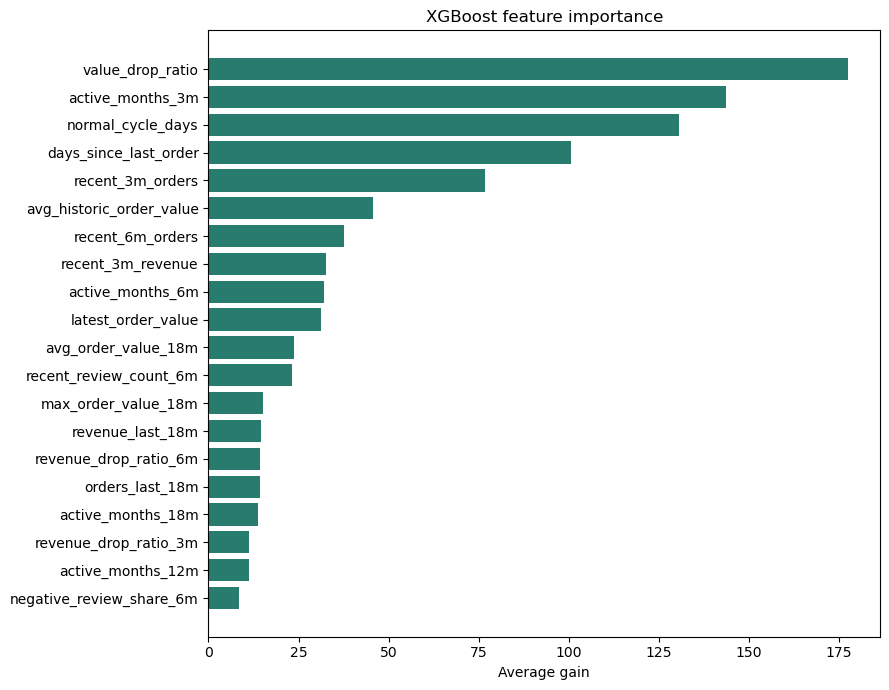

In [8]:
top_k_rows = []
ranked_positions = np.argsort(-test_probability)
for share in [0.05, 0.10, 0.20]:
    k = max(1, int(np.ceil(len(y_test) * share)))
    selected = ranked_positions[:k]
    selected_actual = y_test.iloc[selected]
    top_k_rows.append({
        'top_share': share,
        'accounts_contacted': k,
        'precision_at_k': float(selected_actual.mean()),
        'recall_at_k': float(selected_actual.sum() / max(int(y_test.sum()), 1)),
        'lift_vs_prevalence': float(selected_actual.mean() / max(test_prevalence, 1e-12)),
    })
top_k_results = pd.DataFrame(top_k_rows).set_index('top_share')
display(top_k_results.style.format('{:.3f}'))

booster = model.get_booster()
gain_by_feature = booster.get_score(importance_type='gain')
splits_by_feature = booster.get_score(importance_type='weight')
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'average_gain': [gain_by_feature.get(feature, 0.0) for feature in feature_cols],
    'split_count': [splits_by_feature.get(feature, 0.0) for feature in feature_cols],
}).sort_values('average_gain', ascending=False).reset_index(drop=True)
display(feature_importance.head(20))

plt.figure(figsize=(9, 7))
top_importance = feature_importance.head(20).sort_values('average_gain')
plt.barh(top_importance['feature'], top_importance['average_gain'], color='#287C6E')
plt.xlabel('Average gain')
plt.title('XGBoost feature importance')
plt.tight_layout()
plt.show()

## Per-account prediction drivers
XGBoost's `pred_contribs` gives signed contributions for each prediction. Positive log-odds contributions push the account toward high risk; negative contributions push it away. These are local model explanations, not causal reasons. We keep the top three drivers in each direction per scored account-month.

In [9]:
import xgboost as xgb

booster = model.get_booster()
test_matrix = xgb.DMatrix(X_test, feature_names=feature_cols)
contribution_matrix = booster.predict(test_matrix, pred_contribs=True)
feature_contributions = contribution_matrix[:, :-1]
bias_contribution = contribution_matrix[:, -1]

# SHAP contributions are additive in raw margin (log-odds), before the logistic transform.
margin = model.predict(X_test, output_margin=True)
assert np.allclose(feature_contributions.sum(axis=1) + bias_contribution, margin, atol=1e-4)

explanation_rows = []
feature_values = X_test.to_numpy()
for row_index, row_contributions in enumerate(feature_contributions):
    positive_indices = [i for i in np.argsort(-row_contributions) if row_contributions[i] > 0][:3]
    negative_indices = [i for i in np.argsort(row_contributions) if row_contributions[i] < 0][:3]
    explanation = {
        'account_id': test_df.iloc[row_index]['account_id'],
        'snapshot_month': test_df.iloc[row_index]['snapshot_month'],
        'target_month': test_df.iloc[row_index]['target_month'],
        'actual_high_risk': int(y_test.iloc[row_index]),
        'high_risk_probability': float(test_probability[row_index]),
        'bias_log_odds': float(bias_contribution[row_index]),
    }
    for rank in range(3):
        if rank < len(positive_indices):
            feature_index = positive_indices[rank]
            explanation[f'risk_driver_{rank + 1}'] = feature_cols[feature_index]
            explanation[f'risk_driver_{rank + 1}_value'] = feature_values[row_index, feature_index]
            explanation[f'risk_driver_{rank + 1}_log_odds'] = float(row_contributions[feature_index])
        if rank < len(negative_indices):
            feature_index = negative_indices[rank]
            explanation[f'protective_factor_{rank + 1}'] = feature_cols[feature_index]
            explanation[f'protective_factor_{rank + 1}_value'] = feature_values[row_index, feature_index]
            explanation[f'protective_factor_{rank + 1}_log_odds'] = float(row_contributions[feature_index])
    explanation_rows.append(explanation)

local_explanations = pd.DataFrame(explanation_rows)
latest_snapshot = local_explanations['snapshot_month'].max()
latest_snapshot_actions = local_explanations[
    local_explanations['snapshot_month'].eq(latest_snapshot)
].sort_values('high_risk_probability', ascending=False)
print(f'Explained {len(local_explanations):,} holdout account-month predictions.')
print(f'Latest actionable snapshot: {latest_snapshot.date()} ({len(latest_snapshot_actions):,} accounts).')
display(latest_snapshot_actions.head(10))

Explained 26,816 holdout account-month predictions.
Latest actionable snapshot: 2018-07-31 (9,241 accounts).


,account_id,snapshot_month,target_month,actual_high_risk,high_risk_probability,bias_log_odds,risk_driver_1,risk_driver_1_value,risk_driver_1_log_odds,protective_factor_1,protective_factor_1_value,protective_factor_1_log_odds,risk_driver_2,risk_driver_2_value,risk_driver_2_log_odds,protective_factor_2,protective_factor_2_value,protective_factor_2_log_odds,risk_driver_3,risk_driver_3_value,risk_driver_3_log_odds,protective_factor_3,protective_factor_3_value,protective_factor_3_log_odds
17168,A41185,2018-07-31,2018-08-31,1,0.987752,0.00516,value_drop_ratio,0.172231,1.555395,normal_cycle_days,91.0,-0.329342,days_since_last_order,225.000000,0.850064,latest_review_vs_prior_avg,-2.000000,-0.040391,avg_order_value_18m,756.653333,0.728201,NaN,NaN,NaN
12362,A23953,2018-07-31,2018-08-31,1,0.986721,0.00516,days_since_last_order,232.000000,1.055936,normal_cycle_days,62.0,-0.136740,value_drop_ratio,0.203933,1.047780,active_months_3m,0.000000,-0.000505,avg_order_value_18m,863.695000,0.685013,NaN,NaN,NaN
18879,A57300,2018-07-31,2018-08-31,1,0.984218,0.00516,value_drop_ratio,0.123783,2.005751,normal_cycle_days,128.0,-0.518975,avg_order_value_18m,857.296667,0.826062,recent_3m_revenue,149.900000,-0.032318,avg_historic_order_value,1210.995000,0.741647,review_score_trend_3m,NaN,-0.014387
22638,A79074,2018-07-31,2018-08-31,1,0.983254,0.00516,value_drop_ratio,0.065725,2.181215,normal_cycle_days,231.0,-0.693507,avg_historic_order_value,1513.895000,0.860514,recent_3m_revenue,99.500000,-0.025244,avg_order_value_18m,1042.430000,0.840589,latest_order_value,99.50,-0.013024
22127,A76829,2018-07-31,2018-08-31,1,0.982888,0.00516,days_since_last_order,214.000000,1.119701,normal_cycle_days,65.0,-0.187939,value_drop_ratio,0.127491,1.060378,latest_order_value,109.000000,-0.038104,avg_order_value_18m,668.472500,0.574655,NaN,NaN,NaN
21927,A75802,2018-07-31,2018-08-31,1,0.981972,0.00516,value_drop_ratio,0.062277,2.074569,normal_cycle_days,139.0,-0.544663,avg_historic_order_value,971.633333,0.803859,negative_review_share_6m,1.000000,-0.028983,avg_order_value_18m,743.852500,0.684831,recent_3m_revenue,60.51,-0.008261
22755,A79603,2018-07-31,2018-08-31,1,0.981896,0.00516,value_drop_ratio,0.223700,1.441495,normal_cycle_days,86.0,-0.330764,days_since_last_order,209.000000,0.866462,latest_review_vs_prior_avg,-2.000000,-0.041419,avg_order_value_18m,562.966667,0.711989,NaN,NaN,NaN
9871,A15063,2018-07-31,2018-08-31,1,0.980845,0.00516,value_drop_ratio,0.021997,0.933563,revenue_drop_ratio_6m,0.0,-0.080936,days_since_last_order,231.000000,0.821758,normal_cycle_days,39.000000,-0.029462,avg_order_value_18m,855.212500,0.738220,latest_review_vs_prior_avg,-1.00,-0.012205
12906,A25804,2018-07-31,2018-08-31,1,0.980761,0.00516,value_drop_ratio,0.266990,2.056226,normal_cycle_days,125.0,-0.568932,avg_historic_order_value,823.963333,0.855368,revenue_drop_ratio_6m,0.466179,-0.142030,avg_order_value_18m,672.970000,0.795806,recent_3m_revenue,219.99,-0.033925
26234,A95930,2018-07-31,2018-08-31,1,0.980278,0.00516,value_drop_ratio,0.109272,1.945307,normal_cycle_days,105.0,-0.483124,avg_order_value_18m,561.972500,0.799963,latest_order_value,79.000000,-0.044258,avg_historic_order_value,722.963333,0.782868,recent_3m_revenue,79.00,-0.039662


## Save scored accounts and explanations
The holdout exports support model evaluation and manual action review. Contributions are signed log-odds effects for this model, not causal explanations.

In [10]:
predictions = test_df[['account_id', 'snapshot_month', 'target_month']].copy()
predictions['actual_high_risk'] = y_test.to_numpy()
predictions['actual_churn'] = y_churn_test.to_numpy()
predictions['actual_loss'] = y_loss_test.to_numpy()
predictions['predicted_high_risk'] = test_prediction
predictions['high_risk_probability'] = test_probability
predictions['churn_probability'] = test_churn_probability
predictions['loss_probability'] = test_loss_probability
predictions = predictions.sort_values('high_risk_probability', ascending=False)

predictions_path = OUTPUT_DIR / 'high_risk_test_predictions.csv'
importance_path = OUTPUT_DIR / 'high_risk_feature_importance.csv'
explanations_path = OUTPUT_DIR / 'high_risk_local_explanations.csv'
actions_path = OUTPUT_DIR / 'high_risk_latest_snapshot_actions.csv'
current_scoring_path = OUTPUT_DIR / 'current_account_risk_scores.csv'

predictions.to_csv(predictions_path, index=False)
feature_importance.to_csv(importance_path, index=False)
local_explanations.to_csv(explanations_path, index=False)
latest_snapshot_actions.to_csv(actions_path, index=False)
current_scoring.to_csv(current_scoring_path, index=False)

print(f'Saved holdout predictions: {predictions_path} ({len(predictions):,} rows)')
print(f'Saved global feature importance: {importance_path}')
print(f'Saved per-account explanations: {explanations_path} ({len(local_explanations):,} rows)')
print(f'Saved latest holdout action list: {actions_path} ({len(latest_snapshot_actions):,} rows)')
print(f'Saved current scoring list with eligibility gate: {current_scoring_path} ({len(current_scoring):,} rows)')
display(current_scoring.head(15))

Saved holdout predictions: /Users/sofievium/Library/CloudStorage/OneDrive-CBS-CopenhagenBusinessSchool/CBS/Master/Data Science/Exchange/UvA/Courses/Theories of Business Information Technology Management/Heineken Challenge/outputs/high_risk_test_predictions.csv (26,816 rows)
Saved global feature importance: /Users/sofievium/Library/CloudStorage/OneDrive-CBS-CopenhagenBusinessSchool/CBS/Master/Data Science/Exchange/UvA/Courses/Theories of Business Information Technology Management/Heineken Challenge/outputs/high_risk_feature_importance.csv
Saved per-account explanations: /Users/sofievium/Library/CloudStorage/OneDrive-CBS-CopenhagenBusinessSchool/CBS/Master/Data Science/Exchange/UvA/Courses/Theories of Business Information Technology Management/Heineken Challenge/outputs/high_risk_local_explanations.csv (26,816 rows)
Saved latest holdout action list: /Users/sofievium/Library/CloudStorage/OneDrive-CBS-CopenhagenBusinessSchool/CBS/Master/Data Science/Exchange/UvA/Courses/Theories of Busines

,account_id,snapshot_month,eligibility_order_count_18m,eligible,score_status,orders_last_18m,revenue_last_18m,avg_order_value_18m,max_order_value_18m,days_since_last_order,normal_cycle_days,recent_3m_orders,recent_6m_orders,revenue_drop_ratio_3m,revenue_drop_ratio_6m,recent_3m_revenue,active_months_3m,active_months_6m,active_months_12m,active_months_18m,latest_order_value,avg_historic_order_value,value_drop_ratio,recent_review_count_6m,latest_review_vs_prior_avg,review_score_trend_3m,negative_review_share_6m,account_revenue_18m,account_importance_score,high_risk_probability,churn_probability,loss_probability,risk_driver_1,risk_driver_1_value,risk_driver_1_log_odds,protective_factor_1,protective_factor_1_value,protective_factor_1_log_odds,risk_driver_2,risk_driver_2_value,risk_driver_2_log_odds,protective_factor_2,protective_factor_2_value,protective_factor_2_log_odds,risk_driver_3,risk_driver_3_value,risk_driver_3_log_odds,protective_factor_3,protective_factor_3_value,protective_factor_3_log_odds,predicted_high_risk,priority_score,priority_rank
0,A37550,2018-08-31,32,1,eligible_for_scoring,32.0,4935.41,154.231562,1146.00,355.0,5.0,0.0,0.0,NaN,0.000000,0.00,0.0,0.0,1.0,7.0,53.87,157.469032,0.342099,0.0,-3.064516,NaN,NaN,4935.41,0.985723,0.987767,0.988875,0.042881,days_since_last_order,355.0,1.570967,value_drop_ratio,0.342099,-0.072521,normal_cycle_days,5.0,1.204828,latest_order_value,53.87,-0.012262,revenue_drop_ratio_3m,NaN,0.198734,None,None,None,1.0,0.980715,1.0
1,A23953,2018-08-31,4,1,eligible_for_scoring,4.0,3454.78,863.695000,2999.99,263.0,62.0,0.0,0.0,NaN,0.000000,0.00,0.0,0.0,2.0,4.0,219.90,1078.293333,0.203933,0.0,-3.333333,NaN,NaN,3454.78,0.968510,0.990916,0.965323,0.989410,days_since_last_order,263.0,1.438059,normal_cycle_days,62.0,-0.106357,value_drop_ratio,0.203933,0.979245,latest_order_value,219.9,-0.003432,avg_order_value_18m,863.695,0.729529,None,None,None,1.0,0.975314,2.0
2,A17506,2018-08-31,6,1,eligible_for_scoring,6.0,7400.98,1233.496667,6499.00,111.0,37.0,0.0,3.0,0.000000,1.052007,0.00,0.0,2.0,3.0,5.0,130.00,1454.196000,0.089396,4.0,0.400000,NaN,0.000000,7400.98,0.996264,0.974448,0.883200,0.981910,value_drop_ratio,0.089396,0.978643,revenue_drop_ratio_3m,0.0,-0.059255,avg_order_value_18m,1233.496667,0.822979,active_months_18m,5.0,-0.032955,days_since_last_order,111.0,0.554854,orders_last_18m,6.0,-0.009303,1.0,0.972627,3.0
3,A22775,2018-08-31,27,1,eligible_for_scoring,27.0,3704.76,137.213333,1300.00,347.0,4.0,0.0,0.0,NaN,0.000000,0.00,0.0,0.0,1.0,7.0,99.99,138.645000,0.721194,0.0,0.035714,NaN,NaN,3704.76,0.972913,0.983160,0.982012,0.032647,days_since_last_order,347.0,1.414514,value_drop_ratio,0.721194,-0.122715,normal_cycle_days,4.0,1.303306,latest_order_value,99.99,-0.046046,revenue_last_18m,3704.76,0.231692,latest_review_vs_prior_avg,0.035714,-0.023948,1.0,0.969845,4.0
4,A35340,2018-08-31,3,1,eligible_for_scoring,3.0,4451.89,1483.963333,4099.99,120.0,55.0,0.0,2.0,0.000000,21.270585,0.00,0.0,2.0,3.0,3.0,152.00,2149.945000,0.070699,2.0,0.000000,NaN,0.000000,4451.89,0.981853,0.978362,0.803701,0.983464,value_drop_ratio,0.070699,1.396537,normal_cycle_days,55.0,-0.188102,avg_order_value_18m,1483.963333,0.806891,revenue_drop_ratio_3m,0.0,-0.032135,days_since_last_order,120.0,0.551691,latest_order_value,152.0,-0.011661,1.0,0.969485,5.0
5,A04559,2018-08-31,5,1,eligible_for_scoring,5.0,4434.77,886.954000,3999.90,88.0,128.0,1.0,3.0,0.346210,4.116720,89.98,1.0,2.0,3.0,4.0,89.98,1086.197500,0.082839,3.0,1.000000,2.0,0.333333,4434.77,0.981520,0.974485,0.004703,0.987482,value_drop_ratio,0.082839,2.061393,normal_cycle_days,128.0,-0.70215,avg_order_value_18m,886.954,0.805603,latest_order_value,89.98,-0.034807,avg_historic_order_value,1086.1975,0.651078,review_score_trend_3m,2.0,-0.013744,1.0,0.965480,6.0
6,A89114,2018-08-31,5,1,eligible_for_scoring,5.0,3836.28,767.256000,3597.00,48.0,98.5,1.0,1.0,NaN,0.151603,31.50,1.0,1.0,2.0,3.0,31.50,951.195000,0.033116,1.0,1.250000,NaN,0.000000,3836.28,0.974848,0.977762,0.002694,0.988028

In [11]:
current_scoring_path = OUTPUT_DIR / 'current_account_risk_scores.csv'
current_contributions_path = OUTPUT_DIR / 'current_account_feature_contributions.csv'
current_scoring.to_csv(current_scoring_path, index=False)
current_feature_contributions.to_csv(current_contributions_path, index=False)
print(f'Saved all-account risk and priority table: {current_scoring_path} ({len(current_scoring):,} rows)')
print(f'Saved per-account feature contributions: {current_contributions_path} ({len(current_feature_contributions):,} rows)')
display(current_scoring.head(15))

Saved all-account risk and priority table: /Users/sofievium/Library/CloudStorage/OneDrive-CBS-CopenhagenBusinessSchool/CBS/Master/Data Science/Exchange/UvA/Courses/Theories of Business Information Technology Management/Heineken Challenge/outputs/current_account_risk_scores.csv (14,989 rows)
Saved per-account feature contributions: /Users/sofievium/Library/CloudStorage/OneDrive-CBS-CopenhagenBusinessSchool/CBS/Master/Data Science/Exchange/UvA/Courses/Theories of Business Information Technology Management/Heineken Challenge/outputs/current_account_feature_contributions.csv (210,694 rows)


,account_id,snapshot_month,eligibility_order_count_18m,eligible,score_status,orders_last_18m,revenue_last_18m,avg_order_value_18m,max_order_value_18m,days_since_last_order,normal_cycle_days,recent_3m_orders,recent_6m_orders,revenue_drop_ratio_3m,revenue_drop_ratio_6m,recent_3m_revenue,active_months_3m,active_months_6m,active_months_12m,active_months_18m,latest_order_value,avg_historic_order_value,value_drop_ratio,recent_review_count_6m,latest_review_vs_prior_avg,review_score_trend_3m,negative_review_share_6m,account_revenue_18m,account_importance_score,high_risk_probability,churn_probability,loss_probability,risk_driver_1,risk_driver_1_value,risk_driver_1_log_odds,protective_factor_1,protective_factor_1_value,protective_factor_1_log_odds,risk_driver_2,risk_driver_2_value,risk_driver_2_log_odds,protective_factor_2,protective_factor_2_value,protective_factor_2_log_odds,risk_driver_3,risk_driver_3_value,risk_driver_3_log_odds,protective_factor_3,protective_factor_3_value,protective_factor_3_log_odds,predicted_high_risk,priority_score,priority_rank
0,A37550,2018-08-31,32,1,eligible_for_scoring,32.0,4935.41,154.231562,1146.00,355.0,5.0,0.0,0.0,NaN,0.000000,0.00,0.0,0.0,1.0,7.0,53.87,157.469032,0.342099,0.0,-3.064516,NaN,NaN,4935.41,0.985723,0.987767,0.988875,0.042881,days_since_last_order,355.0,1.570967,value_drop_ratio,0.342099,-0.072521,normal_cycle_days,5.0,1.204828,latest_order_value,53.87,-0.012262,revenue_drop_ratio_3m,NaN,0.198734,None,None,None,1.0,0.980715,1.0
1,A23953,2018-08-31,4,1,eligible_for_scoring,4.0,3454.78,863.695000,2999.99,263.0,62.0,0.0,0.0,NaN,0.000000,0.00,0.0,0.0,2.0,4.0,219.90,1078.293333,0.203933,0.0,-3.333333,NaN,NaN,3454.78,0.968510,0.990916,0.965323,0.989410,days_since_last_order,263.0,1.438059,normal_cycle_days,62.0,-0.106357,value_drop_ratio,0.203933,0.979245,latest_order_value,219.9,-0.003432,avg_order_value_18m,863.695,0.729529,None,None,None,1.0,0.975314,2.0
2,A17506,2018-08-31,6,1,eligible_for_scoring,6.0,7400.98,1233.496667,6499.00,111.0,37.0,0.0,3.0,0.000000,1.052007,0.00,0.0,2.0,3.0,5.0,130.00,1454.196000,0.089396,4.0,0.400000,NaN,0.000000,7400.98,0.996264,0.974448,0.883200,0.981910,value_drop_ratio,0.089396,0.978643,revenue_drop_ratio_3m,0.0,-0.059255,avg_order_value_18m,1233.496667,0.822979,active_months_18m,5.0,-0.032955,days_since_last_order,111.0,0.554854,orders_last_18m,6.0,-0.009303,1.0,0.972627,3.0
3,A22775,2018-08-31,27,1,eligible_for_scoring,27.0,3704.76,137.213333,1300.00,347.0,4.0,0.0,0.0,NaN,0.000000,0.00,0.0,0.0,1.0,7.0,99.99,138.645000,0.721194,0.0,0.035714,NaN,NaN,3704.76,0.972913,0.983160,0.982012,0.032647,days_since_last_order,347.0,1.414514,value_drop_ratio,0.721194,-0.122715,normal_cycle_days,4.0,1.303306,latest_order_value,99.99,-0.046046,revenue_last_18m,3704.76,0.231692,latest_review_vs_prior_avg,0.035714,-0.023948,1.0,0.969845,4.0
4,A35340,2018-08-31,3,1,eligible_for_scoring,3.0,4451.89,1483.963333,4099.99,120.0,55.0,0.0,2.0,0.000000,21.270585,0.00,0.0,2.0,3.0,3.0,152.00,2149.945000,0.070699,2.0,0.000000,NaN,0.000000,4451.89,0.981853,0.978362,0.803701,0.983464,value_drop_ratio,0.070699,1.396537,normal_cycle_days,55.0,-0.188102,avg_order_value_18m,1483.963333,0.806891,revenue_drop_ratio_3m,0.0,-0.032135,days_since_last_order,120.0,0.551691,latest_order_value,152.0,-0.011661,1.0,0.969485,5.0
5,A04559,2018-08-31,5,1,eligible_for_scoring,5.0,4434.77,886.954000,3999.90,88.0,128.0,1.0,3.0,0.346210,4.116720,89.98,1.0,2.0,3.0,4.0,89.98,1086.197500,0.082839,3.0,1.000000,2.0,0.333333,4434.77,0.981520,0.974485,0.004703,0.987482,value_drop_ratio,0.082839,2.061393,normal_cycle_days,128.0,-0.70215,avg_order_value_18m,886.954,0.805603,latest_order_value,89.98,-0.034807,avg_historic_order_value,1086.1975,0.651078,review_score_trend_3m,2.0,-0.013744,1.0,0.965480,6.0
6,A89114,2018-08-31,5,1,eligible_for_scoring,5.0,3836.28,767.256000,3597.00,48.0,98.5,1.0,1.0,NaN,0.151603,31.50,1.0,1.0,2.0,3.0,31.50,951.195000,0.033116,1.0,1.250000,NaN,0.000000,3836.28,0.974848,0.977762,0.002694,0.988028

In [12]:
current_scoring_path = OUTPUT_DIR / 'current_account_risk_scores.csv'
current_contributions_path = OUTPUT_DIR / 'current_account_feature_contributions.csv'
priority_queue_path = OUTPUT_DIR / 'current_account_priority_queue.csv'
current_scoring.to_csv(current_scoring_path, index=False)
current_feature_contributions.to_csv(current_contributions_path, index=False)
priority_columns = [
    'account_id', 'snapshot_month', 'eligibility_order_count_18m', 'eligible', 'score_status',
    'high_risk_probability', 'churn_probability', 'loss_probability', 'predicted_high_risk',
    'account_revenue_18m', 'account_importance_score', 'priority_score', 'priority_rank',
    'risk_driver_1', 'risk_driver_2', 'risk_driver_3',
]
current_priority_queue = current_scoring[priority_columns].copy()
current_priority_queue.to_csv(priority_queue_path, index=False)
print(f'Saved full audit score table: {current_scoring_path} ({len(current_scoring):,} rows)')
print(f'Saved per-account feature importance: {current_contributions_path} ({len(current_feature_contributions):,} rows)')
print(f'Saved compact rep priority queue: {priority_queue_path} ({len(current_priority_queue):,} rows)')
display(current_priority_queue.head(15))

Saved full audit score table: /Users/sofievium/Library/CloudStorage/OneDrive-CBS-CopenhagenBusinessSchool/CBS/Master/Data Science/Exchange/UvA/Courses/Theories of Business Information Technology Management/Heineken Challenge/outputs/current_account_risk_scores.csv (14,989 rows)
Saved per-account feature importance: /Users/sofievium/Library/CloudStorage/OneDrive-CBS-CopenhagenBusinessSchool/CBS/Master/Data Science/Exchange/UvA/Courses/Theories of Business Information Technology Management/Heineken Challenge/outputs/current_account_feature_contributions.csv (210,694 rows)
Saved compact rep priority queue: /Users/sofievium/Library/CloudStorage/OneDrive-CBS-CopenhagenBusinessSchool/CBS/Master/Data Science/Exchange/UvA/Courses/Theories of Business Information Technology Management/Heineken Challenge/outputs/current_account_priority_queue.csv (14,989 rows)


,account_id,snapshot_month,eligibility_order_count_18m,eligible,score_status,high_risk_probability,churn_probability,loss_probability,predicted_high_risk,account_revenue_18m,account_importance_score,priority_score,priority_rank,risk_driver_1,risk_driver_2,risk_driver_3
0,A37550,2018-08-31,32,1,eligible_for_scoring,0.987767,0.988875,0.042881,1.0,4935.41,0.985723,0.980715,1.0,days_since_last_order,normal_cycle_days,revenue_drop_ratio_3m
1,A23953,2018-08-31,4,1,eligible_for_scoring,0.990916,0.965323,0.989410,1.0,3454.78,0.968510,0.975314,2.0,days_since_last_order,value_drop_ratio,avg_order_value_18m
2,A17506,2018-08-31,6,1,eligible_for_scoring,0.974448,0.883200,0.981910,1.0,7400.98,0.996264,0.972627,3.0,value_drop_ratio,avg_order_value_18m,days_since_last_order
3,A22775,2018-08-31,27,1,eligible_for_scoring,0.983160,0.982012,0.032647,1.0,3704.76,0.972913,0.969845,4.0,days_since_last_order,normal_cycle_days,revenue_last_18m
4,A35340,2018-08-31,3,1,eligible_for_scoring,0.978362,0.803701,0.983464,1.0,4451.89,0.981853,0.969485,5.0,value_drop_ratio,avg_order_value_18m,days_since_last_order
5,A04559,2018-08-31,5,1,eligible_for_scoring,0.974485,0.004703,0.987482,1.0,4434.77,0.981520,0.965480,6.0,value_drop_ratio,avg_order_value_18m,avg_historic_order_value
6,A89114,2018-08-31,5,1,eligible_for_scoring,0.977762,0.002694,0.988028,1.0,3836.28,0.974848,0.965466,7.0,value_drop_ratio,avg_order_value_18m,avg_historic_order_value
7,A09750,2018-08-31,10,1,eligible_for_scoring,0.980113,0.976901,0.220514,1.0,3392.55,0.967309,0.964093,8.0,days_since_last_order,avg_order_value_18m,normal_cycle_days
8,A76829,2018-08-31,4,1,eligible_for_scoring,0.989385,0.957374,0.989823,1.0,2673.89,0.946894,0.963114,9.0,days_since_last_order,value_drop_ratio,avg_order_value_18m
9,A03813,2018-08-31,5,1,eligible_for_scoring,0.980528,0.940778,0.990062,1.0,3104.50,0.960705,0.961263,10.0,days_since_last_order,avg_order_value_18m,value_drop_ratio
